## Import Fungsi

In [2]:
from src.utils.path_config import (
    ARTIFACTS_DIR,
)

from src.evaluation.analysis.load_results import (
    load_evaluation_results
)

from src.evaluation.analysis.distribution import (
    plot_all_metrics,
    plot_metric_distribution
)

from src.evaluation.analysis.comparison import (
    compare_experiments
)

from src.evaluation.analysis.per_class_summary import (
    build_per_class_summary
)

from src.evaluation.analysis.ranking import (
    plot_class_ranking
)

from src.evaluation.analysis.per_class_comparison import (
    compare_per_class_metric,
    rank_difficult_classes,
    rank_disagreement_classes,
    rank_consensus_difficult_classes,
    rank_consensus_easy_classes
)

## Result Evaluation Path

In [15]:
RESULTS_PATH = (
    ARTIFACTS_DIR /
      "evaluations" /
      "mobilenetv2_legacy_gradcam_eval_20260623_010533" /
      "results.csv"
)

## Load Evaluation Result

In [16]:
dataframe = load_evaluation_results(
    results_csv=RESULTS_PATH
)

## Set Ouput Directory

In [13]:
OUTPUT_DIR = (
    ARTIFACTS_DIR /
      "evaluations" /
      "mobilenetv2_gradcam_eval_20260621_132927" /
      "histogram"
)

## Generate Single Metric Histogram

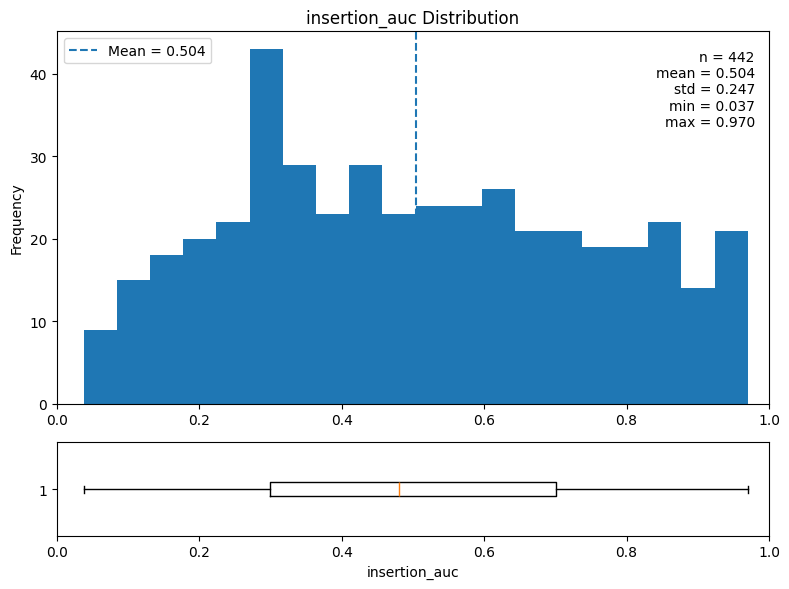

In [17]:
plot_metric_distribution(
    dataframe=dataframe,
    metric_name="insertion_auc",
    output_dir=None
)

## Generate All Metric Histogram

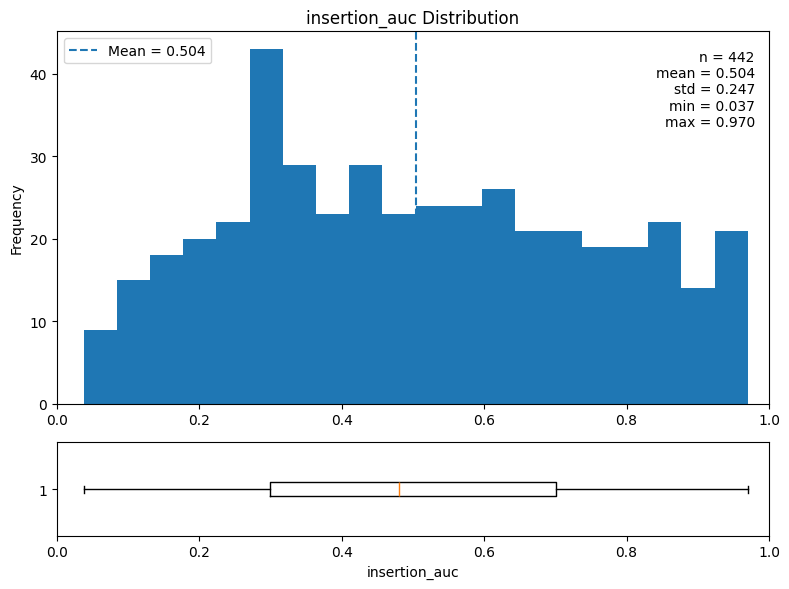

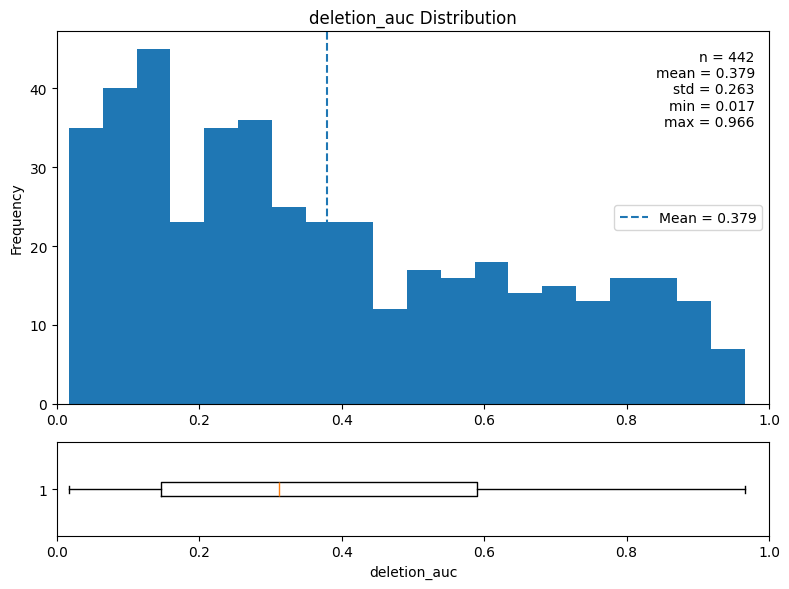

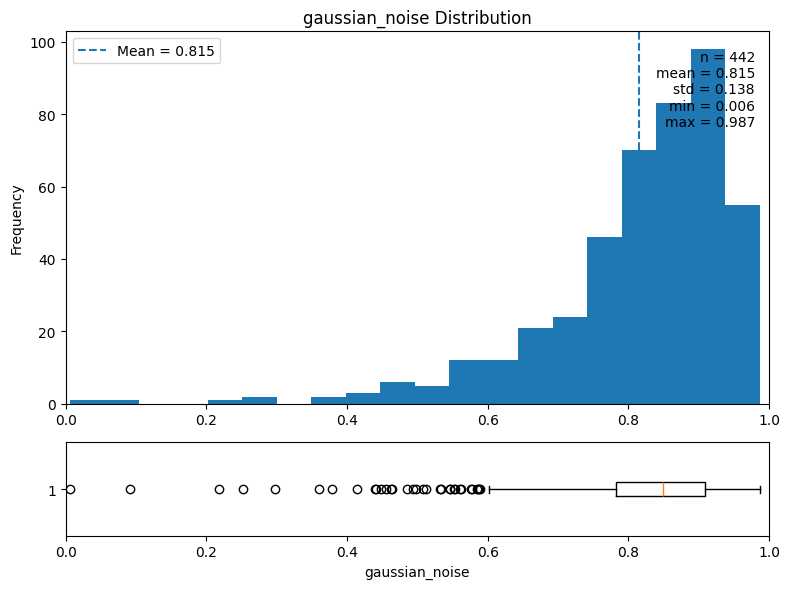

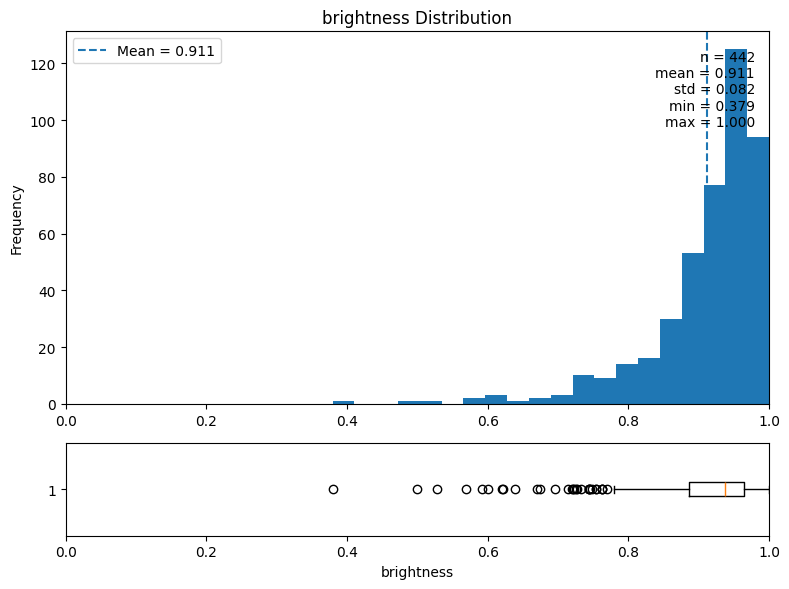

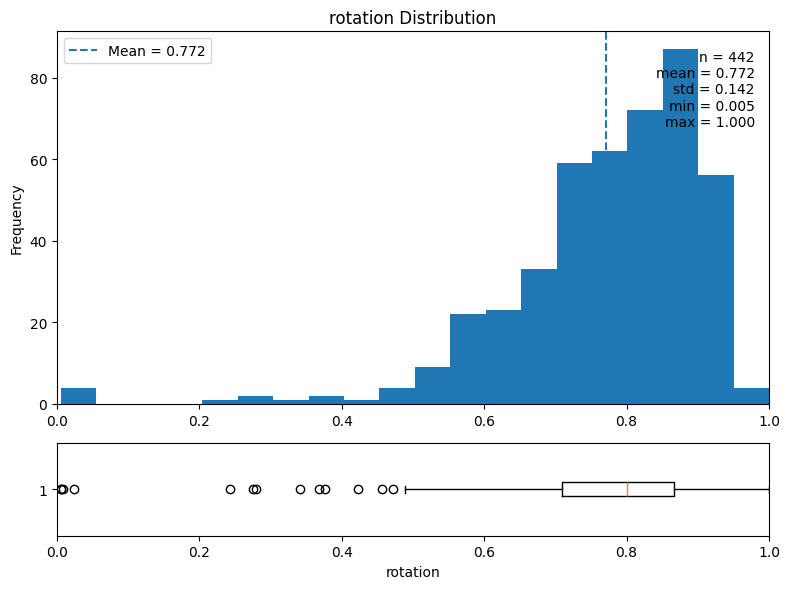

In [18]:
plot_all_metrics(
    dataframe=dataframe,
    output_dir=None
)

## Result Comparison

In [5]:
comparison = compare_experiments(
    {
        "MobileNetV2 GradCAM":
            ARTIFACTS_DIR /
            "evaluations" /
            "mobilenetv2_legacy_gradcam_eval_20260623_010533" /
            "summary.json",

        "MobileNetV2 LIME":
            ARTIFACTS_DIR /
            "evaluations" /
            "mobilenetv2_legacy_lime_eval_20260623_053728" /
            "summary.json",

        "ResNet50 GradCAM":
            ARTIFACTS_DIR /
            "evaluations" /
            "resnet50_legacy_gradcam_eval_20260623_015708" /
            "summary.json",

        "ResNet50 LIME":
            ARTIFACTS_DIR /
            "evaluations" /
            "resnet50_legacy_lime_eval_20260623_125236" /
            "summary.json"
    }
)

comparison

,experiment,insertion_auc,deletion_auc,gaussian_noise,brightness,rotation
0,MobileNetV2 GradCAM,0.504131,0.379396,0.814893,0.911266,0.771619
1,MobileNetV2 LIME,0.482237,0.324198,0.378159,0.411162,0.277663
2,ResNet50 GradCAM,0.593006,0.421233,0.883173,0.919708,0.759865
3,ResNet50 LIME,0.516126,0.366875,0.382928,0.412184,0.273758


## Per Class Summary

In [20]:
per_class = (
    build_per_class_summary(
        dataframe
    )
)

per_class

,ground_truth,samples,insertion_auc,deletion_auc,gaussian_noise,brightness,rotation
0,batik_betawi,23,0.728320,0.660884,0.746464,0.911202,0.747406
1,batik_bokor_kencono,23,0.505781,0.278698,0.830273,0.886274,0.748120
2,batik_buketan,23,0.718602,0.680077,0.797536,0.879276,0.744994
3,batik_dayak,21,0.392222,0.229632,0.771743,0.909308,0.719932
4,batik_jlamprang,21,0.295680,0.220632,0.838707,0.946935,0.837221
5,batik_kawung,22,0.471438,0.345199,0.880482,0.920518,0.847414
6,batik_liong,23,0.905077,0.708824,0.779826,0.898374,0.761873
7,batik_mega_mendung,23,0.712522,0.618077,0.854722,0.960384,0.790468
8,batik_parang,22,0.420139,0.300293,0.766298,0.881459,0.780972
9,batik_sekarjagad,20,0.433182,0.372346,0.761729,0.884612,0.742304


## Ranking Class

### Ranking All Class

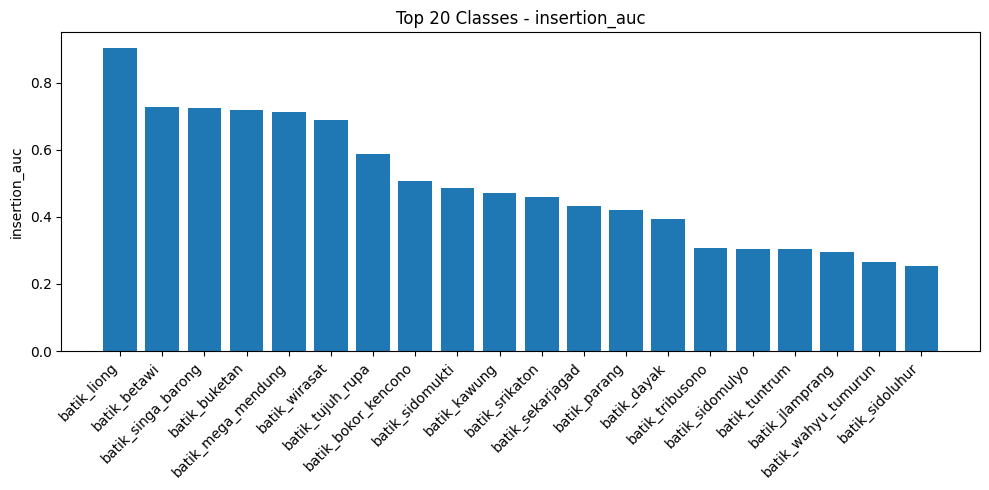

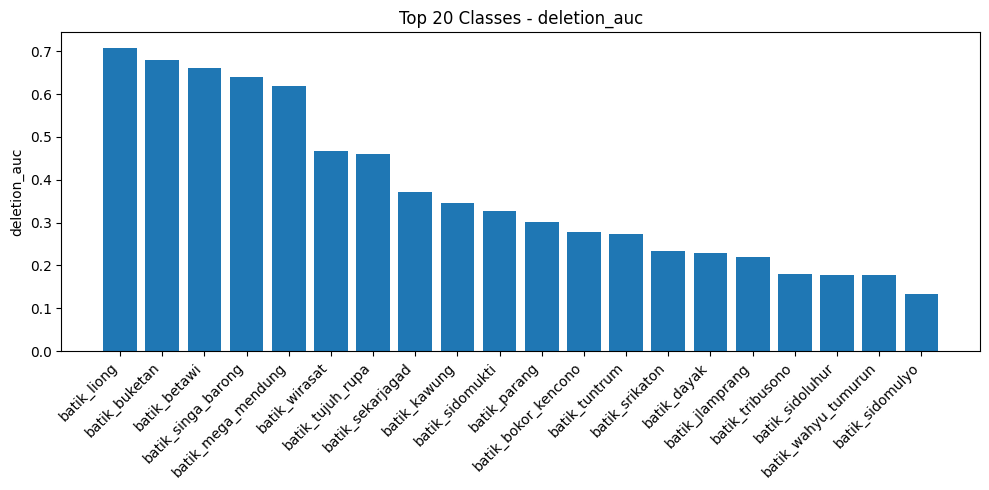

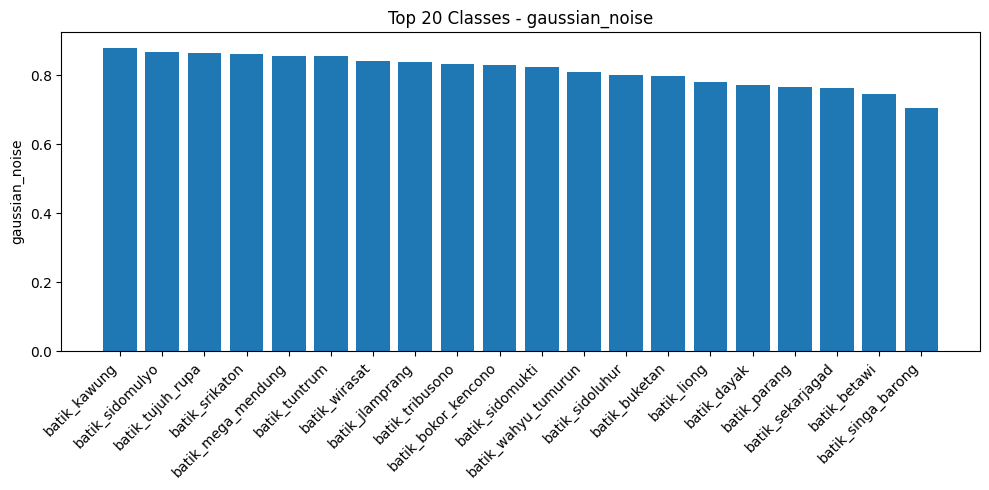

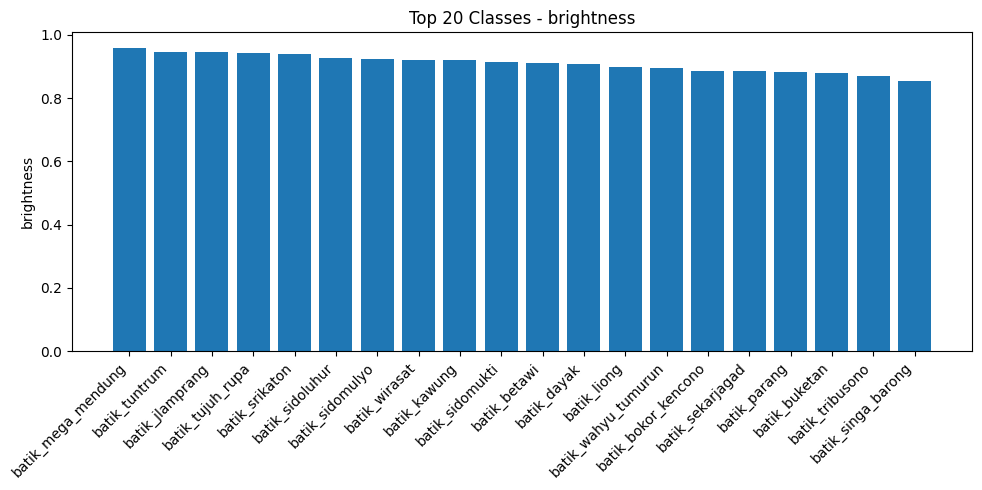

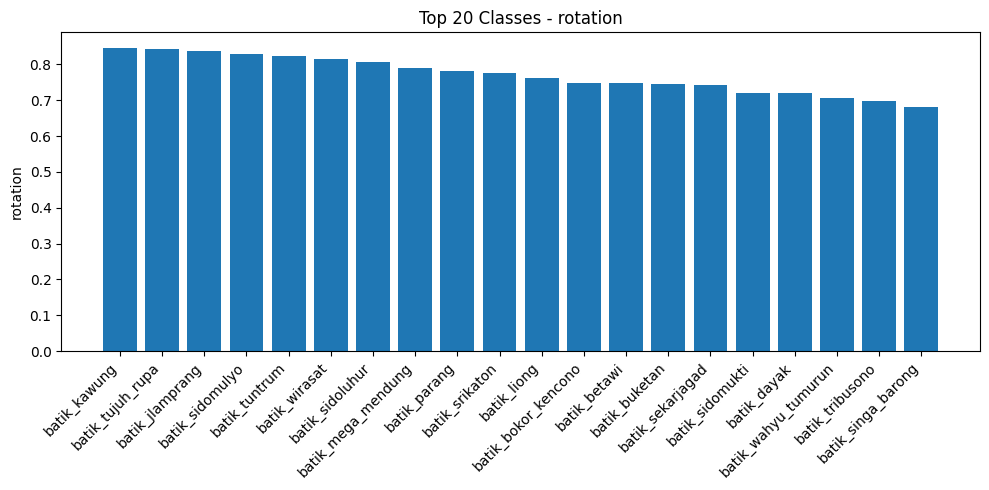

In [30]:
plot_class_ranking(
    per_class,
    metric="insertion_auc",
    top_n=20
)

plot_class_ranking(
    per_class,
    metric="deletion_auc",
    top_n=20
)

plot_class_ranking(
    per_class,
    metric="gaussian_noise",
    top_n=20
)

plot_class_ranking(
    per_class,
    metric="brightness",
    top_n=20
)

plot_class_ranking(
    per_class,
    metric="rotation",
    top_n=20
)

## Per Class Comparison

### Set Result Path

In [22]:
MOBILENETV2_GRADCAM = (
    ARTIFACTS_DIR /
      "evaluations" /
      "mobilenetv2_legacy_gradcam_eval_20260623_010533" /
      "results.csv"
)

MOBILENETV2_LIME = (
    ARTIFACTS_DIR /
      "evaluations" /
      "mobilenetv2_legacy_lime_eval_20260623_053728" /
      "results.csv"
)

RESNET50_GRADCAM = (
    ARTIFACTS_DIR /
      "evaluations" /
      "resnet50_legacy_gradcam_eval_20260623_015708" /
      "results.csv"
)

RESNET50_LIME = (
    ARTIFACTS_DIR /
      "evaluations" /
      "resnet50_legacy_lime_eval_20260623_125236" /
      "results.csv"
)

### Load Result

In [23]:
df_gradcam_mobilenet = load_evaluation_results(
    results_csv=MOBILENETV2_GRADCAM
)

df_lime_mobilenet = load_evaluation_results(
    results_csv=MOBILENETV2_LIME
)

df_gradcam_resnet = load_evaluation_results(
    results_csv=RESNET50_GRADCAM
)

df_lime_resnet = load_evaluation_results(
    results_csv=RESNET50_LIME
)

### Per Class Summary

In [24]:
per_class_gradcam_mobilenet = (
    build_per_class_summary(
        df_gradcam_mobilenet
    )
)

per_class_lime_mobilenet = (
    build_per_class_summary(
        df_lime_mobilenet
    )
)

per_class_gradcam_resnet = (
    build_per_class_summary(
        df_gradcam_resnet
    )
)

per_class_lime_resnet = (
    build_per_class_summary(
        df_lime_resnet
    )
)

### Compare

In [25]:
comparison = (
    compare_per_class_metric(
        summaries={
            "MobileNetV2 GradCAM":
                per_class_gradcam_mobilenet,

            "MobileNetV2 LIME":
                per_class_lime_mobilenet,

            "ResNet50 GradCAM":
                per_class_gradcam_resnet,

            "ResNet50 LIME":
                per_class_lime_resnet
        },
        metric_name="insertion_auc"
    )
)

### Difficult Classes

In [26]:
hardest_classes = (
    rank_difficult_classes(
        comparison
    )
)

hardest_classes.head(20)

,ground_truth,MobileNetV2 GradCAM,MobileNetV2 LIME,ResNet50 GradCAM,ResNet50 LIME,mean_score,std_between_models
0,batik_tribusono,0.305905,0.144859,0.271143,0.237246,0.239788,0.069216
1,batik_sidoluhur,0.252250,0.188710,0.352640,0.275540,0.267285,0.067709
2,batik_sidomulyo,0.305054,0.293872,0.321857,0.302392,0.305794,0.011723
3,batik_jlamprang,0.295680,0.273299,0.415045,0.289928,0.318488,0.065067
4,batik_wahyu_tumurun,0.266379,0.322898,0.453215,0.331250,0.343435,0.078654
5,batik_sekarjagad,0.433182,0.241469,0.516093,0.301941,0.373171,0.124429
6,batik_tuntrum,0.303114,0.380697,0.385266,0.464291,0.383342,0.065828
7,batik_sidomukti,0.485168,0.311612,0.497917,0.278203,0.393225,0.114462
8,batik_srikaton,0.460668,0.329861,0.551596,0.361065,0.425797,0.100723
9,batik_kawung,0.471438,0.477460,0.492053,0.478162,0.479778,0.008722


### Disagreement Classes

In [27]:
disagreement = (
    rank_disagreement_classes(
        comparison
    )
)

disagreement.head(20)

,ground_truth,MobileNetV2 GradCAM,MobileNetV2 LIME,ResNet50 GradCAM,ResNet50 LIME,mean_score,std_between_models
0,batik_wirasat,0.687742,0.371070,0.712707,0.361262,0.533195,0.193179
1,batik_sekarjagad,0.433182,0.241469,0.516093,0.301941,0.373171,0.124429
2,batik_parang,0.420139,0.647243,0.653918,0.658412,0.594928,0.116616
3,batik_sidomukti,0.485168,0.311612,0.497917,0.278203,0.393225,0.114462
4,batik_buketan,0.718602,0.947263,0.894781,0.964777,0.881355,0.112505
5,batik_dayak,0.392222,0.508802,0.458892,0.653376,0.503323,0.110850
6,batik_liong,0.905077,0.705951,0.838746,0.671767,0.780385,0.109988
7,batik_tujuh_rupa,0.586530,0.528590,0.775523,0.656819,0.636865,0.106272
8,batik_srikaton,0.460668,0.329861,0.551596,0.361065,0.425797,0.100723
9,batik_betawi,0.728320,0.734594,0.918183,0.797929,0.794757,0.088086


### Consensus Difficult Classes

In [28]:
difficult = (
    rank_consensus_difficult_classes(
        comparison
    )
)

difficult.head(20)

,ground_truth,MobileNetV2 GradCAM,MobileNetV2 LIME,ResNet50 GradCAM,ResNet50 LIME,mean_score,std_between_models
0,batik_tribusono,0.305905,0.144859,0.271143,0.237246,0.239788,0.069216
1,batik_sidoluhur,0.252250,0.188710,0.352640,0.275540,0.267285,0.067709
2,batik_sidomulyo,0.305054,0.293872,0.321857,0.302392,0.305794,0.011723
3,batik_jlamprang,0.295680,0.273299,0.415045,0.289928,0.318488,0.065067
4,batik_wahyu_tumurun,0.266379,0.322898,0.453215,0.331250,0.343435,0.078654
5,batik_sekarjagad,0.433182,0.241469,0.516093,0.301941,0.373171,0.124429
6,batik_tuntrum,0.303114,0.380697,0.385266,0.464291,0.383342,0.065828
7,batik_sidomukti,0.485168,0.311612,0.497917,0.278203,0.393225,0.114462
8,batik_srikaton,0.460668,0.329861,0.551596,0.361065,0.425797,0.100723
9,batik_kawung,0.471438,0.477460,0.492053,0.478162,0.479778,0.008722


### Consensus Easy Classes

In [29]:
easy = (
    rank_consensus_easy_classes(
        comparison
    )
)

easy.head(20)

,ground_truth,MobileNetV2 GradCAM,MobileNetV2 LIME,ResNet50 GradCAM,ResNet50 LIME,mean_score,std_between_models
0,batik_buketan,0.718602,0.947263,0.894781,0.964777,0.881355,0.112505
1,batik_mega_mendung,0.712522,0.801392,0.892349,0.872920,0.819796,0.081512
2,batik_betawi,0.728320,0.734594,0.918183,0.797929,0.794757,0.088086
3,batik_liong,0.905077,0.705951,0.838746,0.671767,0.780385,0.109988
4,batik_singa_barong,0.724456,0.868399,0.820725,0.678965,0.773136,0.086752
5,batik_tujuh_rupa,0.586530,0.528590,0.775523,0.656819,0.636865,0.106272
6,batik_parang,0.420139,0.647243,0.653918,0.658412,0.594928,0.116616
7,batik_wirasat,0.687742,0.371070,0.712707,0.361262,0.533195,0.193179
8,batik_bokor_kencono,0.505781,0.422845,0.535924,0.601071,0.516406,0.073972
9,batik_dayak,0.392222,0.508802,0.458892,0.653376,0.503323,0.110850
